# 38 — Adding Virgo: SNR budget and sensitive volume of the HLV network (O2, August 2017)

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 20, in the reduced form that the available data allow. One 4096 s chunk with H1, L1 and V1 in science mode (August 2017, away from events; `download_virgo.py`) is whitened with the project's pipeline. With the real PSDs of the three detectors, the real antenna patterns (F₊, Fₓ) and arrival times, the same IMRPhenomD sources of notebook 31 are placed at random sky positions and orientations; the optimal SNR of each source in each detector is computed. From this: (i) the sensitivity of V1 relative to H1 and L1 in the 30–500 Hz band; (ii) the share of the network SNR² contributed by V1; (iii) the sensitive volume (∝ ⟨ρ_net³⟩ at fixed network threshold) of HL, HLV, and the fraction of orientations in which the network SNR of HL is low (< 0.6 of the median) and Virgo rescues it.

**What it does not do.** No search is run on three detectors (no 3-detector background by time slides, no coherent scan), so there is no false-alarm gain or loss: the volume gain is the *ideal* one at a given network SNR threshold, and a real search would raise the threshold when adding a detector; sky localisation is not attempted; one chunk, so one PSD per detector.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import lal
import gwosc_tools as g
g.style()
rng = np.random.default_rng(38)
VC = g.load_json("virgo_chunk.json")
S1 = {}
for d in ("H1", "L1", "V1"):
    x = np.load(os.path.join(g.CACHE, "raw", VC["files"][d])).astype(np.float64); v, f, S = g.whiten_chunk(x); S1[d] = g.psd_1hz(f, S); print(d, "windows:", len(g.make_windows(v)), " NaN:", int(np.isnan(x).sum()))
band = g.BAND; rel = {d: float(np.median(np.sqrt(S1[d][band] / S1["H1"][band]))) for d in S1}
print("median in-band amplitude spectral density relative to H1:", {k: round(v, 2) for k, v in rel.items()})

H1 windows: 4056  NaN: 0


L1 windows: 4056  NaN: 0


V1 windows: 4056  NaN: 0
median in-band amplitude spectral density relative to H1: {'H1': 1.0, 'L1': 0.93, 'V1': 3.72}


In [2]:
z = np.load(os.path.join(g.CACHE, "lib31.npz")); LIB = {k: z[k] for k in z.files}; N = 20000
DET = {"H1": lal.CachedDetectors[lal.LHO_4K_DETECTOR], "L1": lal.CachedDetectors[lal.LLO_4K_DETECTOR], "V1": lal.CachedDetectors[lal.VIRGO_DETECTOR]}
j = rng.integers(0, len(LIB["Hp"]), N); ra = rng.uniform(0, 2 * np.pi, N); dec = np.arcsin(rng.uniform(-1, 1, N)); psi = rng.uniform(0, np.pi, N); gps = rng.uniform(VC["gps_start"], VC["gps_start"] + 4096, N)
RHO = {d: np.zeros(N) for d in DET}
for a in range(N):
    gm = lal.GreenwichMeanSiderealTime(lal.LIGOTimeGPS(float(gps[a])))
    for d in DET:
        fp, fx = lal.ComputeDetAMResponse(DET[d].response, ra[a], dec[a], psi[a], gm); H = fp * LIB["Hp"][j[a]] + fx * LIB["Hc"][j[a]]; RHO[d][a] = np.sqrt(np.sum(4 * np.abs(H) ** 2 * band / S1[d]))
net = lambda ds: np.sqrt(sum(RHO[d] ** 2 for d in ds)); HL, HLV = net(["H1", "L1"]), net(["H1", "L1", "V1"])
share = (RHO["V1"] ** 2 / HLV ** 2)
print("mean share of the network SNR^2 from V1: %.3f ; median %.3f" % (share.mean(), np.median(share)))
vol = lambda r: float(np.mean(r ** 3)); print("sensitive volume ratio HLV / HL at equal network threshold: %.3f" % (vol(HLV) / vol(HL)))
print("sensitive volume ratio HL / H1 alone: %.2f ; HLV / H1: %.2f" % (vol(HL) / vol(RHO["H1"]), vol(HLV) / vol(RHO["H1"])))
low = HL < 0.6 * np.median(HL); print("orientations with HL network SNR < 0.6 median: %.3f ; of those, HLV network SNR above 0.6 of the HL median: %.3f" % (low.mean(), (HLV[low] >= 0.6 * np.median(HL)).mean()))

mean share of the network SNR^2 from V1: 0.096 ; median 0.049
sensitive volume ratio HLV / HL at equal network threshold: 1.063
sensitive volume ratio HL / H1 alone: 5.82 ; HLV / H1: 6.19
orientations with HL network SNR < 0.6 median: 0.231 ; of those, HLV network SNR above 0.6 of the HL median: 0.139


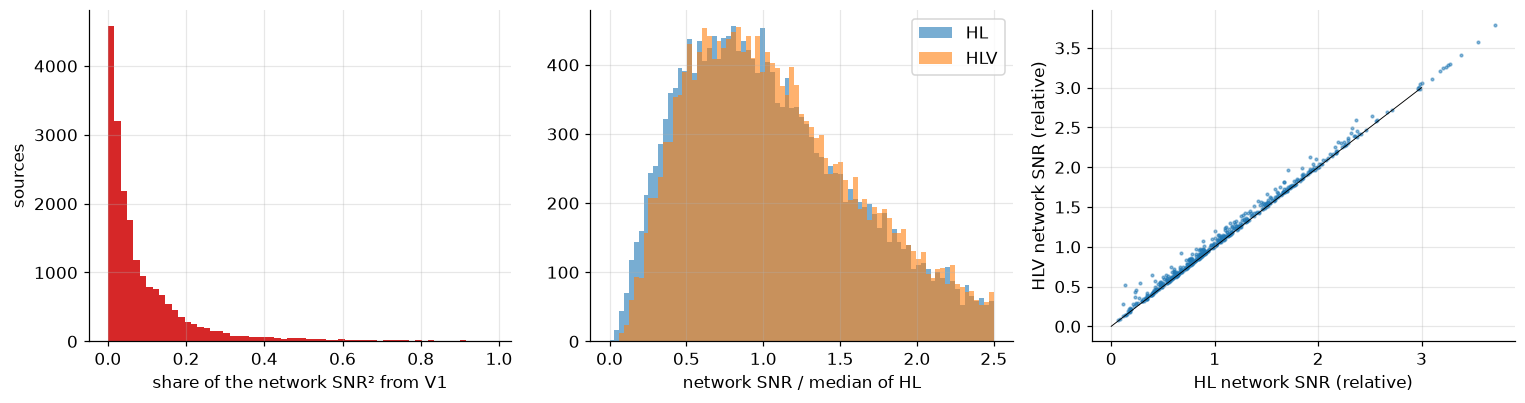

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(share, bins=60, color=g.COLORS["bayes"]); ax[0].set_xlabel("share of the network SNR² from V1"); ax[0].set_ylabel("sources")
ax[1].hist(HL / np.median(HL), bins=np.linspace(0, 2.5, 80), alpha=.6, label="HL"); ax[1].hist(HLV / np.median(HL), bins=np.linspace(0, 2.5, 80), alpha=.6, label="HLV"); ax[1].set_xlabel("network SNR / median of HL"); ax[1].legend()
ax[2].scatter(HL[::40] / np.median(HL), HLV[::40] / np.median(HL), s=3, alpha=.5); ax[2].plot([0, 3], [0, 3], "k-", lw=.6); ax[2].set_xlabel("HL network SNR (relative)"); ax[2].set_ylabel("HLV network SNR (relative)")
fig.tight_layout(); g.savefig(fig, "fig38_virgo"); plt.show()
g.save_json(dict(asd_rel_H1=rel, mean_share_V1=float(share.mean()), median_share_V1=float(np.median(share)), volume_HLV_over_HL=vol(HLV) / vol(HL), volume_HL_over_H1=vol(HL) / vol(RHO["H1"]), volume_HLV_over_H1=vol(HLV) / vol(RHO["H1"]),
                 frac_low_HL=float(low.mean()), frac_rescued=float((HLV[low] >= 0.6 * np.median(HL)).mean()), chunk=VC["gps_start"]), "38_summary.json")

## Output and next step

`results/38_summary.json`, `figures/fig38_virgo`. Next: the final slides.